<a href="https://colab.research.google.com/github/vedikabhusari08/first_repo_vedika/blob/main/MLLab7(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Vedika Bhusari C_C1_13

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

#Display settings
pd.set_option('display.max_columns', None)

In [22]:
df = pd.read_csv("glass.csv")

In [23]:
df.shape

(214, 19)

In [24]:
df.head()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type,Na_Mg_ratio,Ca_Si_ratio,Alkali_total,Heavy_minerals,Mg_Al_interaction,Na_Ca_interaction,log_Ba,log_Fe,Composition_score
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1,3.037861,0.121900,13.70,0.0,4.9390,119.3500,0.0,0.0,99.82
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1,3.858332,0.107658,14.37,0.0,4.8960,108.7587,0.0,0.0,99.89
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1,3.811267,0.106590,13.92,0.0,5.4670,105.2634,0.0,0.0,99.78
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1,3.579945,0.113208,13.78,0.0,4.7601,108.5862,0.0,0.0,99.59
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1,3.665745,0.110427,13.82,0.0,4.4888,107.0889,0.0,0.0,99.83


In [25]:
df.tail()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type,Na_Mg_ratio,Ca_Si_ratio,Alkali_total,Heavy_minerals,Mg_Al_interaction,Na_Ca_interaction,log_Ba,log_Fe,Composition_score
209,1.51623,14.14,0.0,2.88,72.61,0.08,9.18,1.06,0.0,7,14140000.0,0.126429,14.22,1.06,0.0,129.8052,0.722706,0.0,99.95
210,1.51685,14.92,0.0,1.99,73.06,0.00,8.40,1.59,0.0,7,14920000.0,0.114974,14.92,1.59,0.0,125.3280,0.951658,0.0,99.96
211,1.52065,14.36,0.0,2.02,73.42,0.00,8.44,1.64,0.0,7,14360000.0,0.114955,14.36,1.64,0.0,121.1984,0.970779,0.0,99.88
212,1.51651,14.38,0.0,1.94,73.61,0.00,8.48,1.57,0.0,7,14380000.0,0.115202,14.38,1.57,0.0,121.9424,0.943906,0.0,99.98
213,1.51711,14.23,0.0,2.08,73.36,0.00,8.62,1.67,0.0,7,14230000.0,0.117503,14.23,1.67,0.0,122.6626,0.982078,0.0,99.96


In [26]:
df.columns

Index(['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe', 'Type',
       'Na_Mg_ratio', 'Ca_Si_ratio', 'Alkali_total', 'Heavy_minerals',
       'Mg_Al_interaction', 'Na_Ca_interaction', 'log_Ba', 'log_Fe',
       'Composition_score'],
      dtype='object')

In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   RI                 214 non-null    float64
 1   Na                 214 non-null    float64
 2   Mg                 214 non-null    float64
 3   Al                 214 non-null    float64
 4   Si                 214 non-null    float64
 5   K                  214 non-null    float64
 6   Ca                 214 non-null    float64
 7   Ba                 214 non-null    float64
 8   Fe                 214 non-null    float64
 9   Type               214 non-null    int64  
 10  Na_Mg_ratio        214 non-null    float64
 11  Ca_Si_ratio        214 non-null    float64
 12  Alkali_total       214 non-null    float64
 13  Heavy_minerals     214 non-null    float64
 14  Mg_Al_interaction  214 non-null    float64
 15  Na_Ca_interaction  214 non-null    float64
 16  log_Ba             214 non

In [28]:
df.describe()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type,Na_Mg_ratio,Ca_Si_ratio,Alkali_total,Heavy_minerals,Mg_Al_interaction,Na_Ca_interaction,log_Ba,log_Fe,Composition_score
count,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,2.140000e+02,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000
mean,1.518365,13.407850,2.684533,1.444907,72.650935,0.497056,8.956963,0.175047,0.057009,2.780374,2.718508e+06,0.123346,13.904907,0.232056,3.533553,119.775005,0.109371,0.051585,99.874299
std,0.003037,0.816604,1.442408,0.499270,0.774546,0.652192,1.423153,0.497219,0.097439,2.103739,5.544142e+06,0.020075,0.899316,0.501033,2.075049,17.796541,0.283362,0.086087,0.122126
min,1.511150,10.730000,0.000000,0.290000,69.810000,0.000000,5.430000,0.000000,0.000000,1.000000,3.037861e+00,0.074578,11.020000,0.000000,0.000000,74.336700,0.000000,0.000000,99.020000
25%,1.516522,12.907500,2.115000,1.190000,72.280000,0.122500,8.240000,0.000000,0.000000,1.000000,3.653517e+00,0.113198,13.502500,0.000000,2.378700,108.515575,0.000000,0.000000,99.810000
50%,1.517680,13.300000,3.480000,1.360000,72.790000,0.555000,8.600000,0.000000,0.000000,2.000000,3.809981e+00,0.118046,13.800000,0.000000,4.149700,113.256650,0.000000,0.000000,99.890000
75%,1.519157,13.825000,3.600000,1.630000,73.087500,0.610000,9.172500,0.000000,0.100000,3.000000,6.454088e+00,0.127385,14.170000,0.207500,4.922325,129.368700,0.000000,0.095310,99.960000
max,1.533930,17.380000,4.490000,3.500000,75.410000,6.210000,16.190000,3.150000,0.510000,7.000000,1.738000e+07,0.230758,19.230000,3.430000,9.380000,199.137000,1.423108,0.412110,100.100000


In [29]:
df.dtypes

,0
RI,float64
Na,float64
Mg,float64
Al,float64
Si,float64
K,float64
Ca,float64
Ba,float64
Fe,float64
Type,int64


In [30]:
df.isnull().sum()

,0
RI,0
Na,0
Mg,0
Al,0
Si,0
K,0
Ca,0
Ba,0
Fe,0
Type,0


In [31]:
df.duplicated().sum()

np.int64(1)

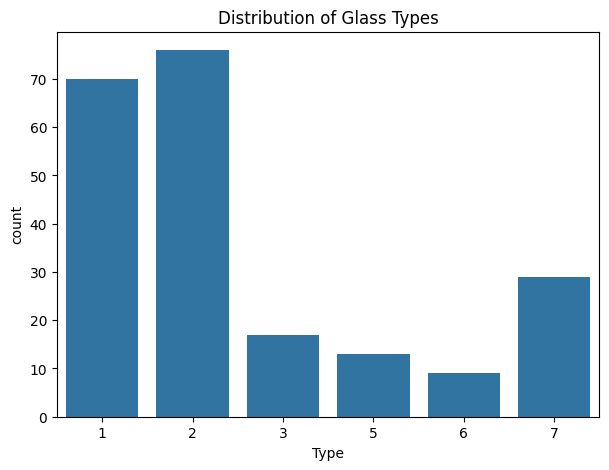

In [32]:

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Type")

plt.title("Distribution of Glass Types")
plt.show()

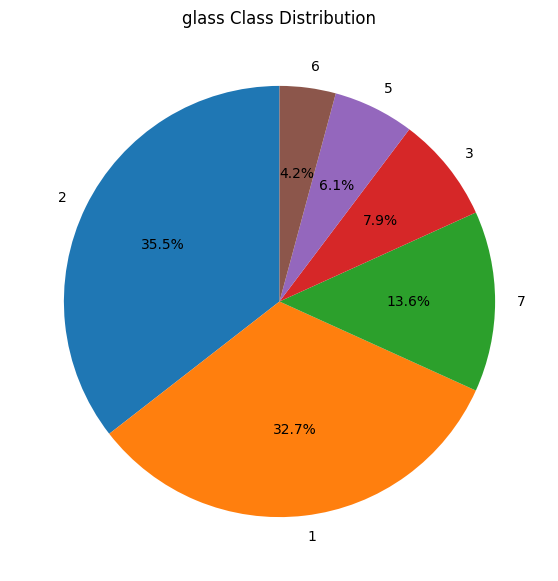

In [33]:
class_counts = df["Type"].value_counts()
plt.figure(figsize=(7,7))

plt.pie(class_counts, labels=class_counts.index, autopct='%1.1f%%', startangle=90)
plt.title("glass Class Distribution")
plt.show()

In [34]:
numerical_features = df.select_dtypes(include=np.number).columns

print("Numerical Features:")
print(numerical_features.tolist())

Numerical Features:
['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe', 'Type', 'Na_Mg_ratio', 'Ca_Si_ratio', 'Alkali_total', 'Heavy_minerals', 'Mg_Al_interaction', 'Na_Ca_interaction', 'log_Ba', 'log_Fe', 'Composition_score']


Histograms

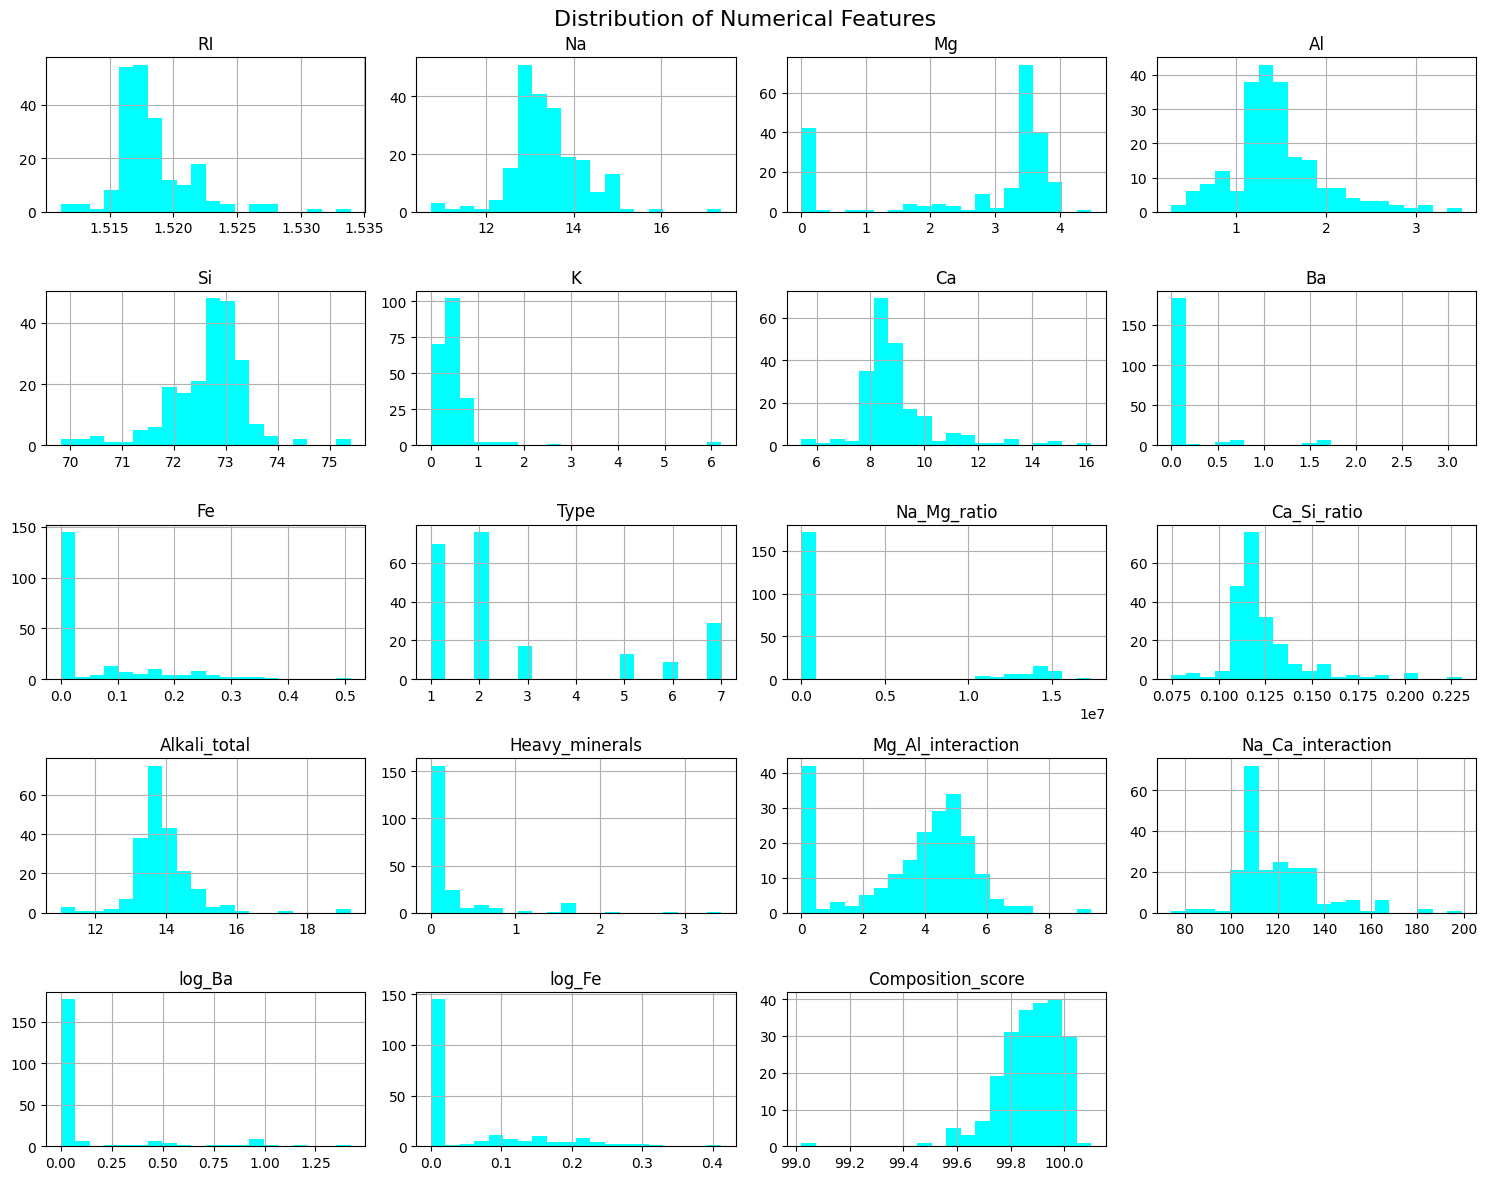

In [35]:
df[numerical_features].hist(figsize=(15,12), bins=20, color='cyan')

plt.suptitle("Distribution of Numerical Features", fontsize=16)

plt.tight_layout()

plt.show()

ValueError: num must be an integer with 1 <= num <= 9, not 10

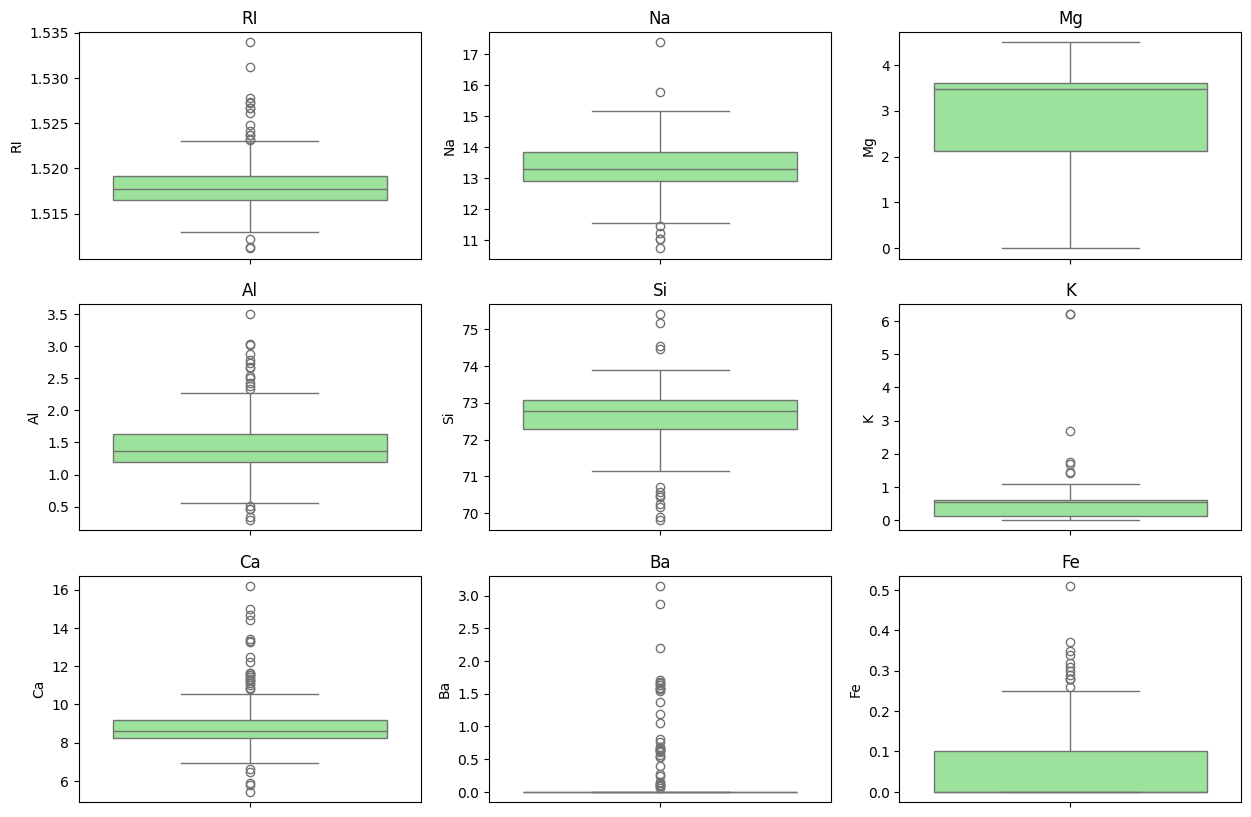

In [36]:
plt.figure(figsize=(15,10))

for i, column in enumerate(numerical_features, 1):
   plt.subplot(3, 3, i)
   sns.boxplot(y=df[column], color='lightgreen')
   plt.title(column)

plt.tight_layout()
plt.show()

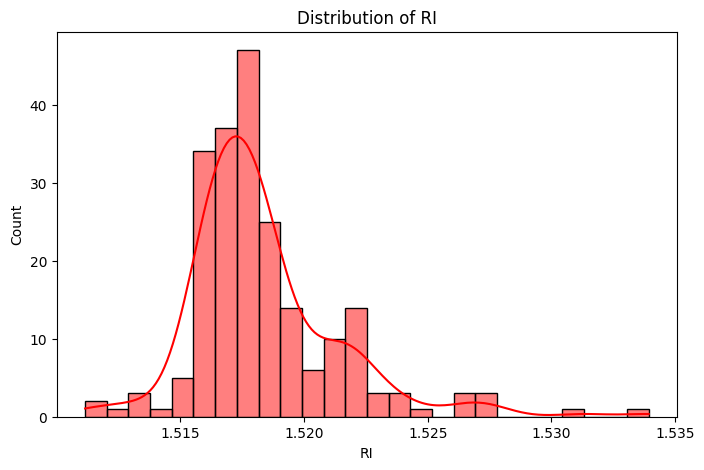

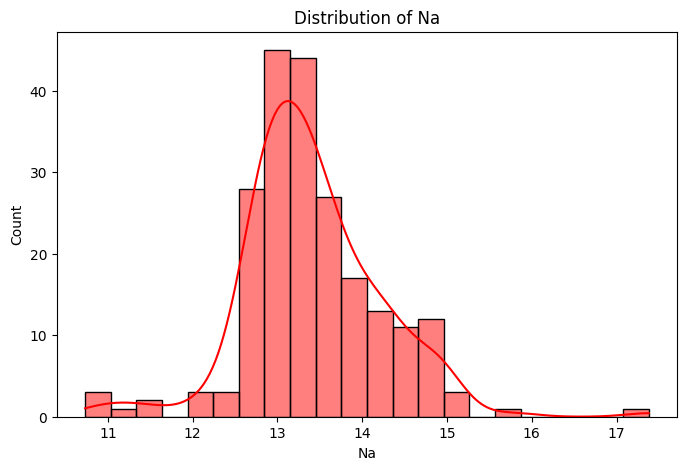

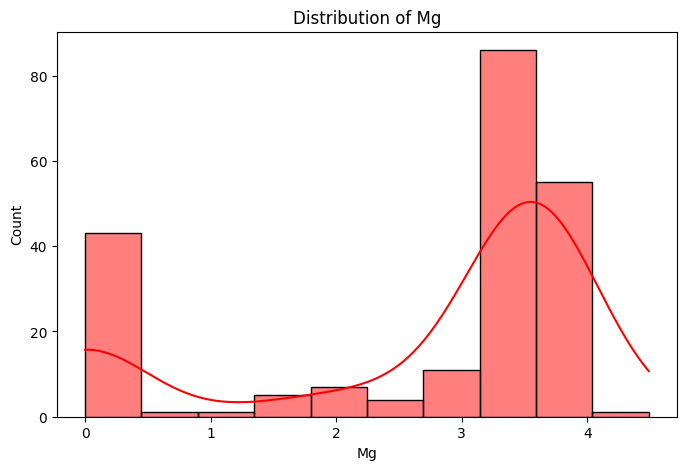

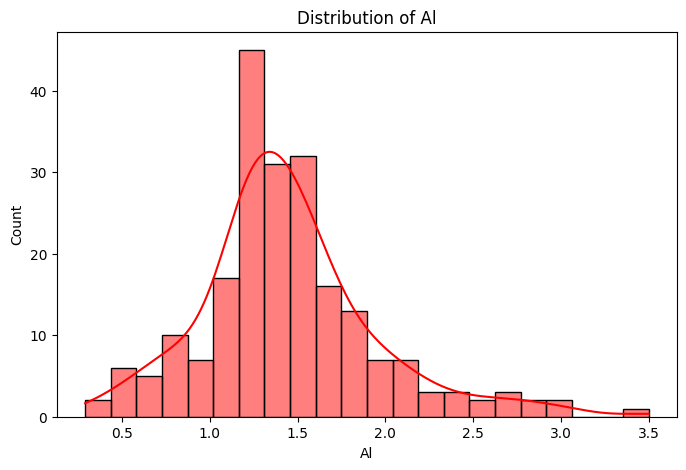

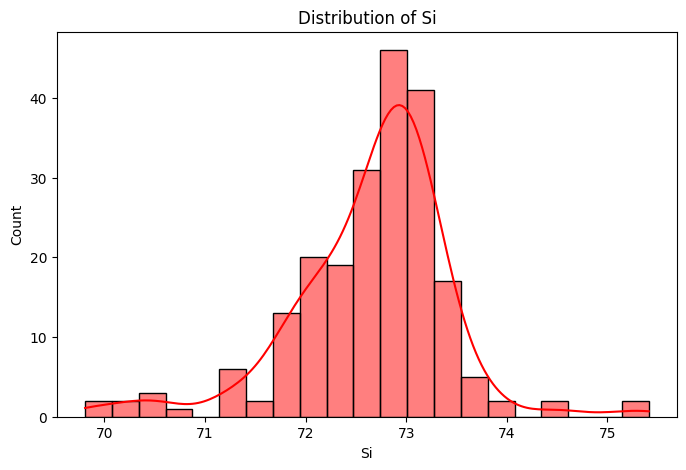

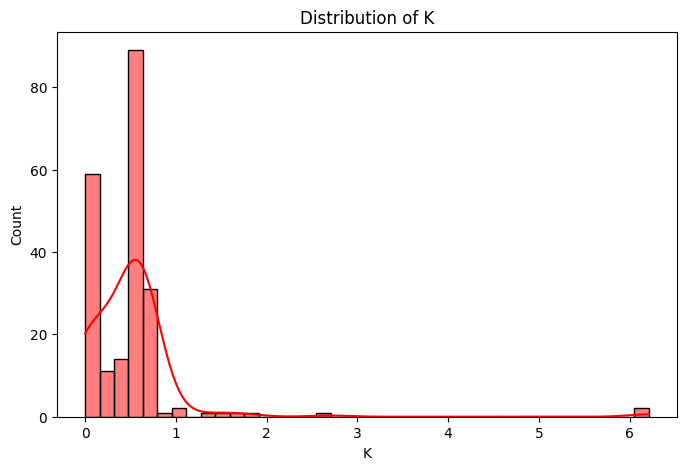

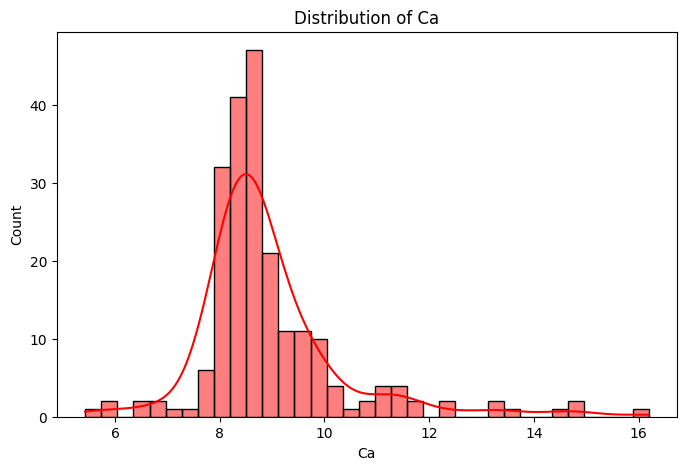

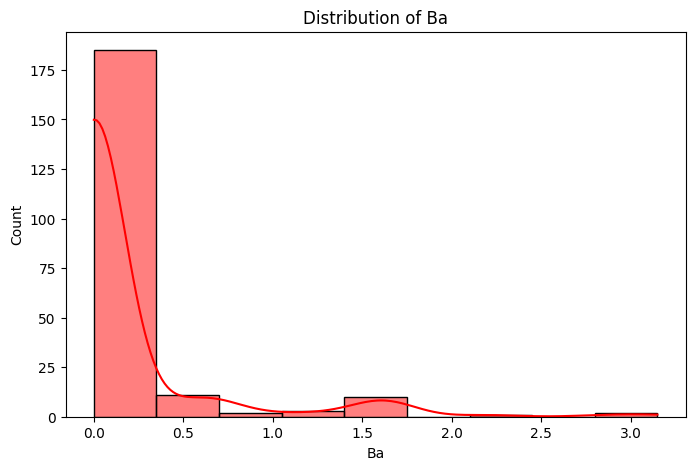

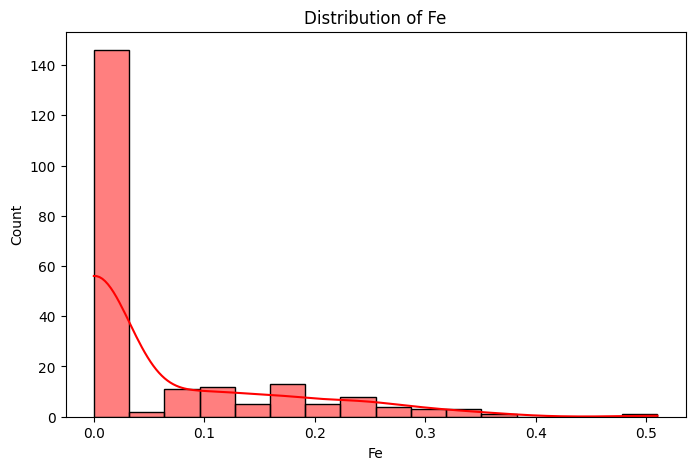

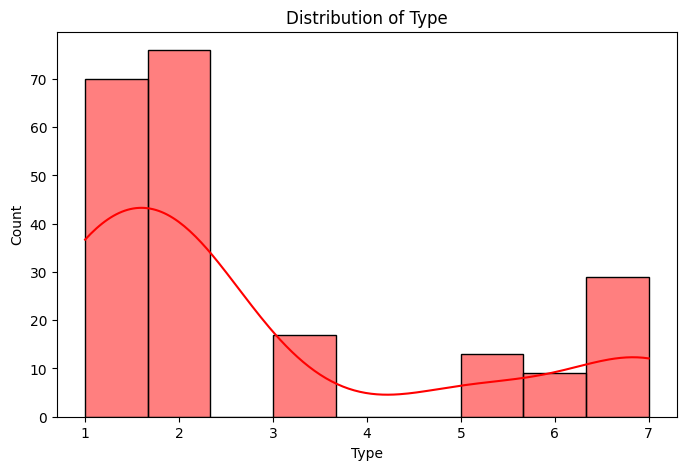

KeyboardInterrupt: 

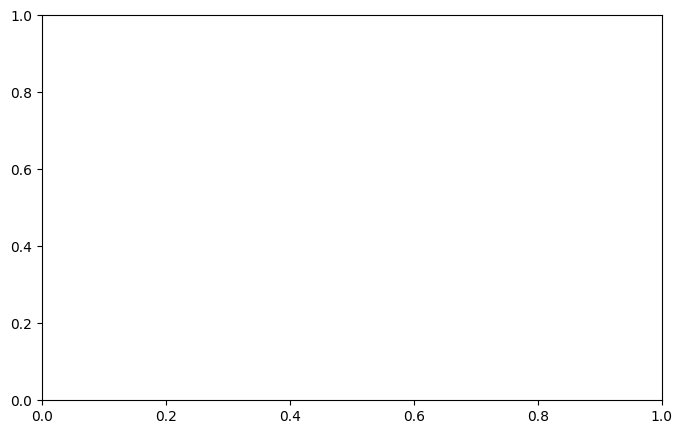

In [37]:
for column in numerical_features:
  plt.figure(figsize=(8,5))
  sns.histplot(data=df, x=column, kde=True, color='red')
  plt.title(f"Distribution of {column}")
  plt.show()

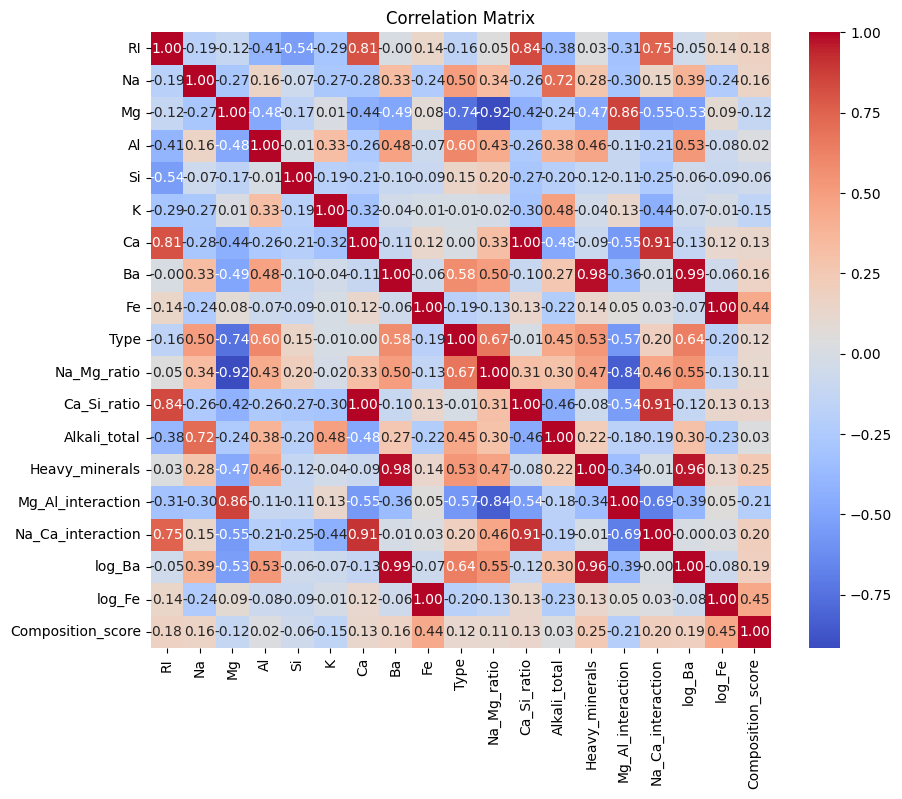

In [38]:
correlation_matrix = df[numerical_features].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

Text(0.5, 1.0, 'Area vs Perimeter')

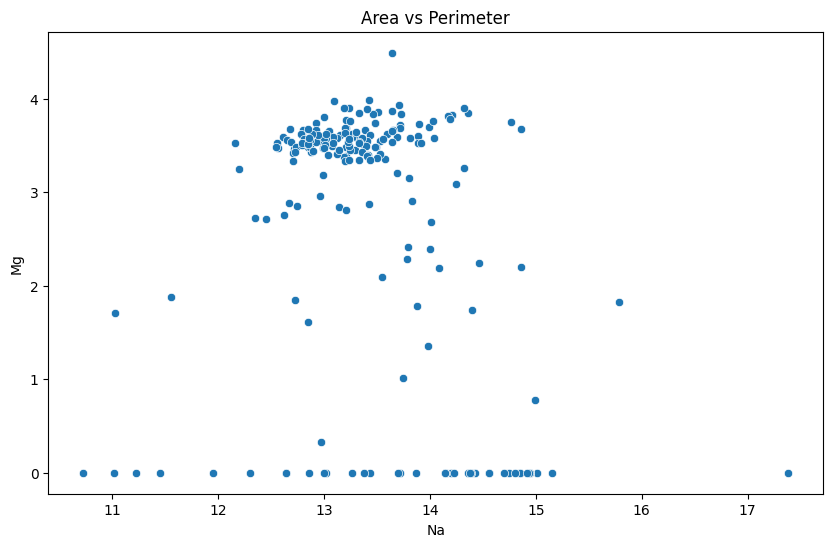

In [39]:
plt.figure(figsize = (10,6))
sns.scatterplot(data=df, x="Na", y="Mg")
plt.title("Area vs Perimeter")

In [40]:
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
df["Type_encoded"] = label_encoder.fit_transform(df["Type"])
print(df[["Type", "Type_encoded"]].head(70))

    Type  Type_encoded
0      1             0
1      1             0
2      1             0
3      1             0
4      1             0
..   ...           ...
65     1             0
66     1             0
67     1             0
68     1             0
69     1             0

[70 rows x 2 columns]


In [41]:
X = df[numerical_features]
y = df["Type_encoded"]

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (214, 19)
Shape of y: (214,)


In [42]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 171
Testing samples: 43


In [43]:
GaussianNB()

GaussianNB()

In [44]:
gnb = GaussianNB()
gnb.fit(X_train, y_train)

GaussianNB()

In [45]:
y_pred = gnb.predict(X_test)

print("Predicted: ")
print(y_pred)

Predicted: 
[5 5 0 5 0 0 0 0 0 0 0 0 5 0 0 5 5 0 0 5 0 0 5 0 0 0 5 5 0 0 0 0 0 0 0 0 0
 0 0 0 0 5 0]


In [46]:
comparison = pd.DataFrame({"Actual": y_test, "Predicted": y_pred})

print(comparison.head(30))

     Actual  Predicted
208       5          5
169       3          5
122       1          0
172       3          5
29        0          0
2         0          0
117       1          0
129       1          0
43        0          0
52        0          0
156       2          0
14        0          0
199       5          5
179       4          0
144       1          0
196       5          5
194       5          5
65        0          0
20        0          0
173       3          5
1         0          0
23        0          0
203       5          5
114       1          0
141       1          0
148       2          0
131       1          5
109       1          5
98        1          0
95        1          0


In [47]:
comparison["Actual_Type"] = label_encoder.inverse_transform(comparison["Actual"])
comparison["Predicted_Type"] = label_encoder.inverse_transform(comparison["Predicted"])
comparison.head(20)

,Actual,Predicted,Actual_Type,Predicted_Type
208,5,5,7,7
169,3,5,5,7
122,1,0,2,1
172,3,5,5,7
29,0,0,1,1
2,0,0,1,1
117,1,0,2,1
129,1,0,2,1
43,0,0,1,1
52,0,0,1,1


In [48]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy: ", accuracy)
print("Accuracy (%): ",accuracy * 100)

Accuracy:  0.4418604651162791
Accuracy (%):  44.18604651162791


In [49]:
recall = recall_score(y_test, y_pred, average='weighted')
print("Recall: ", recall)
print("Recall (%): ", recall * 100)

Recall:  0.4418604651162791
Recall (%):  44.18604651162791


In [50]:
precision = precision_score(y_test, y_pred, average='weighted')
print("Precision: ", precision)
print("Precision (%): ", precision * 100)

Precision:  0.20586680761099363
Precision (%):  20.586680761099363


In [51]:
f1 = f1_score(y_test, y_pred, average='weighted')
print("F1 Score: ", f1)
print("F1 Score (%): ", f1 * 100)

F1 Score:  0.28025932314280616
F1 Score (%):  28.025932314280617


In [52]:
print("==== Model Performance ====")
print("Accuracy: {:.2f}%".format(accuracy * 100))
print("Recall: {:.2f}%".format(recall * 100))
print("Precision: {:.2f}%".format(precision * 100))
print("F1 Score: {:.2f}%".format(f1 * 100))

==== Model Performance ====
Accuracy: 44.19%
Recall: 44.19%
Precision: 20.59%
F1 Score: 28.03%


In [53]:
print("Classification report:\n")
print(classification_report(y_test, y_pred))

Classification report:

              precision    recall  f1-score   support

           0       0.44      1.00      0.61        14
           1       0.00      0.00      0.00        15
           2       0.00      0.00      0.00         3
           3       0.00      0.00      0.00         3
           4       0.00      0.00      0.00         2
           5       0.45      0.83      0.59         6

    accuracy                           0.44        43
   macro avg       0.15      0.31      0.20        43
weighted avg       0.21      0.44      0.28        43



Confusion matrix

In [54]:
from sklearn.metrics import accuracy_score

y_train_pred = gnb.predict(X_train)
y_test_pred = gnb.predict(X_test)
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print("Training Accuracy: ", train_accuracy)
print("Training Accuracy (%): ", train_accuracy * 100)

print("Testing Accuracy: ", test_accuracy)
print("Testing Accuracy (%): ", test_accuracy * 100)

Training Accuracy:  0.4327485380116959
Training Accuracy (%):  43.27485380116959
Testing Accuracy:  0.4418604651162791
Testing Accuracy (%):  44.18604651162791


In [55]:
GaussianNB(priors=None)

GaussianNB()

In [56]:
confusion_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(confusion_matrix)

Confusion Matrix:
[[14  0  0  0  0  0]
 [12  0  0  0  0  3]
 [ 3  0  0  0  0  0]
 [ 0  0  0  0  0  3]
 [ 2  0  0  0  0  0]
 [ 1  0  0  0  0  5]]
